In [ ]:

from google.colab import drive

# Connect Google Drive to Colab
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os

# Location of your SKINDERMO folder in Google Drive
project_path = "/content/drive/MyDrive/SKINDERMO"

# Check whether the folder exists
print("Folder exists:", os.path.exists(project_path))

# Display the uploaded files
if os.path.exists(project_path):
    print("\nFiles inside SKINDERMO:")
    for item in os.listdir(project_path):
        print(item)


Folder exists: True

Files inside SKINDERMO:
HAM10000_images_part_2
HAM10000_metadata.csv
HAM10000_images_part_1


In [ ]:

# Step 5: Check TensorFlow installation


import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices('GPU')))
print("GPUs:", tf.config.list_physical_devices('GPU'))



TensorFlow version: 2.21.0
GPU available: True
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

# Step 8: Load and inspect HAM10000 metadata

import os
import pandas as pd

project_path = "/content/drive/MyDrive/SKINDERMO"
metadata_path = os.path.join(project_path, "HAM10000_metadata.csv")

# Read the metadata CSV file
df = pd.read_csv(metadata_path)

# Display dataset information
print("Total metadata records:", len(df))
print("\nColumn names:")
print(df.columns.tolist())

# Count images in each disease category
print("\nImages per disease category:")
print(df["dx"].value_counts())

# Display the first five rows
print("\nFirst five records:")
print(df.head())


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/SKINDERMO/HAM10000_metadata.csv'

In [ ]:

import os

project_path = "/content/drive/MyDrive/SKINDERMO"

print("Files and folders found:")

for root, dirs, files in os.walk(project_path):
    for file in files:
        if "metadata" in file.lower():
            print(os.path.join(root, file))


Files and folders found:


In [ ]:

import os

print("MyDrive contents:")

path = "/content/drive/MyDrive"

for item in os.listdir(path):
    print(repr(item))


MyDrive contents:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive'

In [ ]:

from google.colab import drive
import os

# Reconnect Google Drive
drive.mount('/content/drive', force_remount=True)

# Check the mount location
print("\nDrive folder exists:",
      os.path.exists('/content/drive'))

print("MyDrive exists:",
      os.path.exists('/content/drive/MyDrive'))

# List available folders
if os.path.exists('/content/drive/MyDrive'):
    print("\nMyDrive contents:")
    print(os.listdir('/content/drive/MyDrive'))


Mounted at /content/drive

Drive folder exists: True
MyDrive exists: True

MyDrive contents:
['Classroom', 'SKINDERMO', 'Colab Notebooks']


In [ ]:

import os

project_path = "/content/drive/MyDrive/SKINDERMO"

print("SKINDERMO folder exists:", os.path.exists(project_path))

print("\nItems inside SKINDERMO:")
for item in os.listdir(project_path):
    print(item)


SKINDERMO folder exists: True

Items inside SKINDERMO:
HAM10000_metadata.csv
HAM10000_images_part_1
HAM10000_images_part_2


In [ ]:

# Step 10: Load HAM10000 metadata

import os
import pandas as pd

project_path = "/content/drive/MyDrive/SKINDERMO"
metadata_path = os.path.join(project_path, "HAM10000_metadata.csv")

# Read the CSV file
df = pd.read_csv(metadata_path)

# Display dataset details
print("Total metadata records:", len(df))

print("\nColumns:")
print(df.columns.tolist())

print("\nImages per disease category:")
print(df["dx"].value_counts())

print("\nFirst five records:")
print(df.head())


Total metadata records: 10015

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Images per disease category:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

First five records:
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear


In [ ]:

# Step 11: Check whether metadata images exist

import os

project_path = "/content/drive/MyDrive/SKINDERMO"

# Image folders
image_folders = [
    os.path.join(project_path, "HAM10000_images_part_1"),
    os.path.join(project_path, "HAM10000_images_part_2")
]

# Collect image filenames
image_files = set()

for folder in image_folders:
    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files.add(os.path.splitext(filename)[0])

# Compare image IDs with available files
metadata_ids = set(df["image_id"].astype(str))
matched_ids = metadata_ids.intersection(image_files)
missing_ids = metadata_ids - image_files

print("Metadata records:", len(df))
print("Unique image IDs:", df["image_id"].nunique())
print("Image files found:", len(image_files))
print("Metadata IDs matched to files:", len(matched_ids))
print("Images missing:", len(missing_ids))


Metadata records: 10015
Unique image IDs: 10015
Image files found: 10045
Metadata IDs matched to files: 10015
Images missing: 0


In [ ]:

# Step 12: Check lesion IDs before splitting

print("Total images:", len(df))
print("Unique lesions:", df["lesion_id"].nunique())
print("Images with missing lesion IDs:", df["lesion_id"].isna().sum())

# Check how many images belong to each lesion
images_per_lesion = df.groupby("lesion_id")["image_id"].count()

print("\nLesions with multiple images:",
      (images_per_lesion > 1).sum())

print("Maximum images for one lesion:",
      images_per_lesion.max())


Total images: 10015
Unique lesions: 7470
Images with missing lesion IDs: 0

Lesions with multiple images: 1956
Maximum images for one lesion: 6


In [ ]:

# Step 13: Split by lesion_id to prevent data leakage

from sklearn.model_selection import GroupShuffleSplit
import os

# First, split off 15% of lesions for testing
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=42
)

train_val_idx, test_idx = next(
    split1.split(df, groups=df["lesion_id"])
)

train_val_df = df.iloc[train_val_idx].copy()
test_df = df.iloc[test_idx].copy()

# Split the remaining data so validation is about 15% overall
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.1765, random_state=42
)

train_idx, val_idx = next(
    split2.split(train_val_df, groups=train_val_df["lesion_id"])
)

train_df = train_val_df.iloc[train_idx].copy()
val_df = train_val_df.iloc[val_idx].copy()

# Check that no lesion occurs in multiple splits
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nLesion overlap checks:")
print("Train and validation:", len(train_lesions & val_lesions))
print("Train and test:", len(train_lesions & test_lesions))
print("Validation and test:", len(val_lesions & test_lesions))


Training images: 6959
Validation images: 1529
Testing images: 1527

Lesion overlap checks:
Train and validation: 0
Train and test: 0
Validation and test: 0


In [ ]:

# Step 14: Save dataset splits for all three models

import os

split_path = "/content/drive/MyDrive/SKINDERMO/splits"
os.makedirs(split_path, exist_ok=True)

train_df.to_csv(
    os.path.join(split_path, "train.csv"), index=False
)

val_df.to_csv(
    os.path.join(split_path, "validation.csv"), index=False
)

test_df.to_csv(
    os.path.join(split_path, "test.csv"), index=False
)

print("Dataset splits saved successfully!")
print("Location:", split_path)
print("Files:", os.listdir(split_path))


Dataset splits saved successfully!
Location: /content/drive/MyDrive/SKINDERMO/splits
Files: ['train.csv', 'validation.csv', 'test.csv']


In [ ]:

# Step 15: Load a small batch of HAM10000 images

import os
import pandas as pd
import tensorflow as tf

project_path = "/content/drive/MyDrive/SKINDERMO"

# Load the saved training split
train_df = pd.read_csv(
    os.path.join(project_path, "splits", "train.csv")
)

# Image folders
image_folders = [
    os.path.join(project_path, "HAM10000_images_part_1"),
    os.path.join(project_path, "HAM10000_images_part_2")
]

# Find the path for an image ID
def find_image_path(image_id):
    for folder in image_folders:
        path = os.path.join(folder, str(image_id) + ".jpg")
        if os.path.exists(path):
            return path
    return None

# Test the first image
sample_id = train_df.iloc[0]["image_id"]
sample_path = find_image_path(sample_id)

print("Sample image ID:", sample_id)
print("Image path:", sample_path)
print("Image exists:", sample_path is not None)

if sample_path is not None:
    image = tf.keras.utils.load_img(
        sample_path, target_size=(224, 224)
    )
    print("Image loaded successfully!")
    print("Image size:", image.size)


Sample image ID: ISIC_0027419
Image path: /content/drive/MyDrive/SKINDERMO/HAM10000_images_part_1/ISIC_0027419.jpg
Image exists: True
Image loaded successfully!
Image size: (224, 224)


In [ ]:

# Step 16: Prepare labels and image preprocessing

import numpy as np
import pandas as pd
import tensorflow as tf
import os

project_path = "/content/drive/MyDrive/SKINDERMO"
split_path = os.path.join(project_path, "splits")

# Load the saved dataset splits
train_df = pd.read_csv(os.path.join(split_path, "train.csv"))
val_df = pd.read_csv(os.path.join(split_path, "validation.csv"))
test_df = pd.read_csv(os.path.join(split_path, "test.csv"))

# Create one consistent mapping for all three models
class_names = sorted(train_df["dx"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

print("Class names:", class_names)
print("Number of classes:", len(class_names))
print("Class mapping:", class_to_index)

# Convert labels into integer IDs
for data in [train_df, val_df, test_df]:
    data["label"] = data["dx"].map(class_to_index)

# Check for unknown labels
print("\nMissing training labels:", train_df["label"].isna().sum())
print("Missing validation labels:", val_df["label"].isna().sum())
print("Missing test labels:", test_df["label"].isna().sum())


Class names: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7
Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}

Missing training labels: 0
Missing validation labels: 0
Missing test labels: 0


In [ ]:

# Step 17: Create a reusable image pipeline

import os
import numpy as np
import tensorflow as tf

project_path = "/content/drive/MyDrive/SKINDERMO"

image_folders = [
    os.path.join(project_path, "HAM10000_images_part_1"),
    os.path.join(project_path, "HAM10000_images_part_2")
]

# Build a lookup table for image paths
image_paths = {}

for folder in image_folders:
    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_id = os.path.splitext(filename)[0]
            image_paths[image_id] = os.path.join(folder, filename)

# Reuse the same class order for every model
class_names = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
class_to_index = {name: i for i, name in enumerate(class_names)}

def make_dataset(dataframe, image_size=224, batch_size=16, training=False):
    paths = [image_paths[x] for x in dataframe["image_id"]]
    labels = dataframe["dx"].map(class_to_index).to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_jpeg(image_bytes, channels=3)
        image = tf.image.resize(image, [image_size, image_size])
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.shuffle(1000, seed=42)

    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

print("Image files indexed:", len(image_paths))
print("Image pipeline function created successfully!")


Image files indexed: 10045
Image pipeline function created successfully!


In [ ]:

# Quick test: load only one image

images, labels = next(iter(
    make_dataset(
        train_df.iloc[:1],
        image_size=224,
        batch_size=1,
        training=False
    )
))

print("Image shape:", images.shape)
print("Label:", labels.numpy())


NameError: name 'make_dataset' is not defined

In [ ]:

import os
import numpy as np
import tensorflow as tf

project_path = "/content/drive/MyDrive/SKINDERMO"

# Reconnect Drive if needed
from google.colab import drive
if not os.path.exists(project_path):
    drive.mount('/content/drive')

# Load the saved training split
import pandas as pd

train_df = pd.read_csv(
    os.path.join(project_path, "splits", "train.csv")
)

# Index image paths
image_paths = {}

for folder_name in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    folder = os.path.join(project_path, folder_name)
    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_id = os.path.splitext(filename)[0]
            image_paths[image_id] = os.path.join(folder, filename)

# Create the image-loading function
class_to_index = {
    "akiec": 0, "bcc": 1, "bkl": 2, "df": 3,
    "mel": 4, "nv": 5, "vasc": 6
}

def make_dataset(dataframe, image_size=224, batch_size=16, training=False):
    paths = [image_paths[x] for x in dataframe["image_id"]]
    labels = dataframe["dx"].map(class_to_index).to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(
            image, channels=3, expand_animations=False
        )
        image = tf.image.resize(image, [image_size, image_size])
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=1)

    if training:
        ds = ds.shuffle(1000, seed=42)

    return ds.batch(batch_size).prefetch(1)

print("Image pipeline recreated successfully.")
print("Images indexed:", len(image_paths))
print("Training records:", len(train_df))


Image pipeline recreated successfully.
Images indexed: 10045
Training records: 6959


In [ ]:

images, labels = next(iter(
    make_dataset(
        train_df.iloc[:1],
        image_size=224,
        batch_size=1
    )
))

print("Image shape:", images.shape)
print("Label:", labels.numpy())


Image shape: (1, 224, 224, 3)
Label: [2]


In [ ]:

# Step 19: Create training and validation datasets

train_ds = make_dataset(
    train_df,
    image_size=224,
    batch_size=16,
    training=True
)

val_df = pd.read_csv(
    "/content/drive/MyDrive/SKINDERMO/splits/validation.csv"
)

val_ds = make_dataset(
    val_df,
    image_size=224,
    batch_size=16,
    training=False
)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Datasets prepared successfully!")


Training batches: 435
Validation batches: 96
Datasets prepared successfully!


In [ ]:

# Step 20: Prepare ResNet50

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models

NUM_CLASSES = 7
IMG_SIZE = 224
BATCH_SIZE = 16

# Load ResNet50 pretrained on ImageNet
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze the pretrained layers initially
base_model.trainable = False

# Build the classification model
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = layers.Lambda(preprocess_input)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

resnet_model = models.Model(inputs, outputs)

# Compile the model
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │        14,343 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,602,055 (90.03 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:

# Step 21: Train ResNet50

import os
import tensorflow as tf

project_path = "/content/drive/MyDrive/SKINDERMO"
model_dir = os.path.join(project_path, "models")
os.makedirs(model_dir, exist_ok=True)

# Save the best model based on validation loss
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(model_dir, "resnet50_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[checkpoint, early_stop]
)


Epoch 1/3
435/435 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6991 - loss: 0.9193
Epoch 1: val_loss improved from None to 1.83996, saving model to /content/drive/MyDrive/SKINDERMO/models/resnet50_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SKINDERMO/models/resnet50_best.keras
435/435 ━━━━━━━━━━━━━━━━━━━━ 2833s 6s/step - accuracy: 0.8243 - loss: 0.5721 - val_accuracy: 0.6821 - val_loss: 1.8400
Epoch 2/3
435/435 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.7377 - loss: 0.9794
Epoch 2: val_loss did not improve from 1.83996
435/435 ━━━━━━━━━━━━━━━━━━━━ 88s 181ms/step - accuracy: 0.8530 - loss: 0.5670 - val_accuracy: 0.6920 - val_loss: 2.5991
Epoch 3/3
435/435 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.7366 - loss: 1.1452
Epoch 3: val_loss did not improve from 1.83996
435/435 ━━━━━━━━━━━━━━━━━━━━ 80s 164ms/step - accuracy: 0.8563 - loss: 0.6440 - val_accuracy: 0.6795 - val_loss: 3.2102


In [ ]:

import pandas as pd
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

# Save the ResNet50 training history
history_df = pd.DataFrame(history_resnet.history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_path = os.path.join(
    project_path, "resnet50_training_history.csv"
)

history_df.to_csv(history_path)

print("ResNet50 history saved to:", history_path)
print(history_df)


NameError: name 'history_resnet' is not defined

In [ ]:

from google.colab import drive
import os

# Reconnect Google Drive
drive.mount('/content/drive')

# Check the saved ResNet50 model
model_path = (
    "/content/drive/MyDrive/SKINDERMO/models/resnet50_best.keras"
)

print("ResNet50 model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model size (MB):", round(os.path.getsize(model_path) / (1024 * 1024), 2))


Mounted at /content/drive
ResNet50 model exists: True
Model size (MB): 90.77


In [ ]:

import pandas as pd
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

# Reconstructed from the training output you shared
history_df = pd.DataFrame({
    "accuracy": [0.8243, 0.8530, 0.8563],
    "loss": [0.5721, 0.5670, 0.6440],
    "val_accuracy": [0.6821, 0.6920, 0.6795],
    "val_loss": [1.8400, 2.5991, 3.2102]
}, index=[1, 2, 3])

history_df.index.name = "epoch"

history_path = os.path.join(
    project_path, "resnet50_training_history_reconstructed.csv"
)

history_df.to_csv(history_path)

print("Reconstructed training history saved!")
print(history_df)


Reconstructed training history saved!
       accuracy    loss  val_accuracy  val_loss
epoch                                          
1        0.8243  0.5721        0.6821    1.8400
2        0.8530  0.5670        0.6920    2.5991
3        0.8563  0.6440        0.6795    3.2102


In [ ]:

# Reload dataset splits after reconnecting Colab

import os
import pandas as pd
import numpy as np
import tensorflow as tf

project_path = "/content/drive/MyDrive/SKINDERMO"
split_path = os.path.join(project_path, "splits")

train_df = pd.read_csv(os.path.join(split_path, "train.csv"))
val_df = pd.read_csv(os.path.join(split_path, "validation.csv"))
test_df = pd.read_csv(os.path.join(split_path, "test.csv"))

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Test records:", len(test_df))
print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


Training records: 6959
Validation records: 1529
Test records: 1527
TensorFlow version: 2.21.0
GPU available: True


In [ ]:

# Rebuild image paths and the dataset pipeline

import os
import numpy as np
import tensorflow as tf

project_path = "/content/drive/MyDrive/SKINDERMO"

image_folders = [
    os.path.join(project_path, "HAM10000_images_part_1"),
    os.path.join(project_path, "HAM10000_images_part_2")
]

# Index all available image files
image_paths = {}

for folder in image_folders:
    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_id = os.path.splitext(filename)[0]
            image_paths[image_id] = os.path.join(folder, filename)

class_to_index = {
    "akiec": 0, "bcc": 1, "bkl": 2, "df": 3,
    "mel": 4, "nv": 5, "vasc": 6
}

def make_dataset(dataframe, image_size=224, batch_size=16, training=False):
    paths = [image_paths[x] for x in dataframe["image_id"]]
    labels = dataframe["dx"].map(class_to_index).to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(
            image, channels=3, expand_animations=False
        )
        image = tf.image.resize(image, [image_size, image_size])
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=1)

    if training:
        ds = ds.shuffle(1000, seed=42)

    return ds.batch(batch_size).prefetch(1)

print("Image paths indexed:", len(image_paths))
print("Dataset pipeline ready!")


Image paths indexed: 10045
Dataset pipeline ready!


In [ ]:

# Step 22: Build DenseNet121

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input

IMG_SIZE = 224
NUM_CLASSES = 7

# Load pretrained DenseNet121
base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers for initial training
base_model.trainable = False

# Build the classification model
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = layers.Lambda(preprocess_input)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

densenet_model = models.Model(inputs, outputs)

# Compile the model
densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

densenet_model.summary()


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         7,175 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,044,679 (26.87 MB)

 Trainable params: 7,175 (28.03 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:

# Step 23: Train DenseNet121

import os
import tensorflow as tf

project_path = "/content/drive/MyDrive/SKINDERMO"
model_dir = os.path.join(project_path, "models")
os.makedirs(model_dir, exist_ok=True)

# Save the best checkpoint based on validation loss
densenet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(model_dir, "densenet121_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

densenet_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_densenet = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[densenet_checkpoint, densenet_early_stop]
)


NameError: name 'train_ds' is not defined

In [ ]:

# Recreate training and validation datasets

train_ds = make_dataset(
    train_df,
    image_size=224,
    batch_size=16,
    training=True
)

val_ds = make_dataset(
    val_df,
    image_size=224,
    batch_size=16,
    training=False
)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))


Training batches: 435
Validation batches: 96


In [ ]:

# Train DenseNet121 and save its best checkpoint

import os
import tensorflow as tf

project_path = "/content/drive/MyDrive/SKINDERMO"
model_dir = os.path.join(project_path, "models")
os.makedirs(model_dir, exist_ok=True)

densenet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(model_dir, "densenet121_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

densenet_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_densenet = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[densenet_checkpoint, densenet_early_stop]
)


Epoch 1/3
435/435 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.5810 - loss: 1.2342
Epoch 1: val_loss improved from None to 1.82996, saving model to /content/drive/MyDrive/SKINDERMO/models/densenet121_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SKINDERMO/models/densenet121_best.keras
435/435 ━━━━━━━━━━━━━━━━━━━━ 6049s 12s/step - accuracy: 0.7586 - loss: 0.7403 - val_accuracy: 0.6861 - val_loss: 1.8300
Epoch 2/3
434/435 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.6441 - loss: 1.1842
Epoch 2: val_loss improved from 1.82996 to 1.74757, saving model to /content/drive/MyDrive/SKINDERMO/models/densenet121_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/SKINDERMO/models/densenet121_best.keras
435/435 ━━━━━━━━━━━━━━━━━━━━ 81s 166ms/step - accuracy: 0.8010 - loss: 0.6475 - val_accuracy: 0.6874 - val_loss: 1.7476
Epoch 3/3
435/435 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.6721 - loss: 1.0651
Epoch 3: val_loss did not improve from 1.74757

In [ ]:

import pandas as pd
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

# Reconstructed from the training output screenshot
densenet_history_df = pd.DataFrame({
    "accuracy": [0.7586, 0.8010, 0.8155],
    "loss": [0.7403, 0.6475, 0.5963],
    "val_accuracy": [0.6861, 0.6874, 0.6900],
    "val_loss": [1.8300, 1.7476, 1.8069]
}, index=[1, 2, 3])

densenet_history_df.index.name = "epoch"

history_path = os.path.join(
    project_path, "densenet121_training_history_reconstructed.csv"
)

densenet_history_df.to_csv(history_path)

print("DenseNet121 history saved:", history_path)
print(densenet_history_df)


OSError: Cannot save file into a non-existent directory: '/content/drive/MyDrive/SKINDERMO'

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

project_path = "/content/drive/MyDrive/SKINDERMO"
os.makedirs(project_path, exist_ok=True)

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("SKINDERMO folder exists:", os.path.exists(project_path))

Mounted at /content/drive
Drive mounted: True
SKINDERMO folder exists: True


In [ ]:
densenet_history_df.to_csv(history_path)
print("DenseNet121 history saved:", history_path)

DenseNet121 history saved: /content/drive/MyDrive/SKINDERMO/densenet121_training_history_reconstructed.csv


In [ ]:
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

for model in ["resnet50_best.keras", "densenet121_best.keras"]:
    path = os.path.join(project_path, "models", model)
    print(model, "exists:", os.path.exists(path))

resnet50_best.keras exists: False
densenet121_best.keras exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

for folder in [
    "/content/drive/MyDrive/SKINDERMO",
    "/content/drive/MyDrive/SKINDERMO/models"
]:
    print("\nFolder:", folder)
    print("Exists:", os.path.exists(folder))
    if os.path.exists(folder):
        print(os.listdir(folder)[:30])

Mounted at /content/drive

Folder: /content/drive/MyDrive/SKINDERMO
Exists: True
['HAM10000_metadata.csv', 'HAM10000_images_part_1', 'HAM10000_images_part_2', 'splits', 'models', 'resnet50_training_history_reconstructed.csv', 'densenet121_training_history_reconstructed.csv']

Folder: /content/drive/MyDrive/SKINDERMO/models
Exists: True
['resnet50_best.keras', 'densenet121_best.keras']


In [ ]:
import os

model_dir = "/content/drive/MyDrive/SKINDERMO/models"

for filename in ["resnet50_best.keras", "densenet121_best.keras"]:
    path = os.path.join(model_dir, filename)
    print(filename, "exists:", os.path.exists(path))
    if os.path.exists(path):
        print("Size (MB):", round(os.path.getsize(path) / (1024 * 1024), 2))

resnet50_best.keras exists: True
Size (MB): 90.77
densenet121_best.keras exists: True
Size (MB): 28.38


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [ ]:
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

print("Dataset metadata:", os.path.exists(
    os.path.join(project_path, "HAM10000_metadata.csv")
))

print("Training splits:", os.path.exists(
    os.path.join(project_path, "splits", "train.csv")
))

print("Validation splits:", os.path.exists(
    os.path.join(project_path, "splits", "validation.csv")
))

print("Test splits:", os.path.exists(
    os.path.join(project_path, "splits", "test.csv")
))

for model in ["resnet50_best.keras", "densenet121_best.keras"]:
    path = os.path.join(project_path, "models", model)
    print(model, ":", os.path.exists(path))

Dataset metadata: True
Training splits: True
Validation splits: True
Test splits: True
resnet50_best.keras : True
densenet121_best.keras : True


In [ ]:
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

for folder in [
    "HAM10000_images_part_1",
    "HAM10000_images_part_2"
]:
    path = os.path.join(project_path, folder)
    print(folder, "exists:", os.path.isdir(path))
    if os.path.isdir(path):
        print("Number of files:", len(os.listdir(path)))

HAM10000_images_part_1 exists: True
Number of files: 5017
HAM10000_images_part_2 exists: True
Number of files: 5028


In [ ]:
import os
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense, Rescaling
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint

# Keep TensorFlow on CPU for this run
tf.config.set_visible_devices([], "GPU")

# Project paths
project_path = "/content/drive/MyDrive/SKINDERMO"
model_dir = os.path.join(project_path, "models")
os.makedirs(model_dir, exist_ok=True)

# Load saved data splits
train_df = pd.read_csv(os.path.join(project_path, "splits", "train.csv"))
val_df = pd.read_csv(os.path.join(project_path, "splits", "validation.csv"))

# Find image files
image_paths = {}
for folder in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    folder_path = os.path.join(project_path, folder)
    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths[os.path.splitext(filename)[0]] = os.path.join(
                folder_path, filename
            )

# Match the seven classes to integer labels
class_to_index = {
    "akiec": 0, "bcc": 1, "bkl": 2, "df": 3,
    "mel": 4, "nv": 5, "vasc": 6
}

# Create image paths and labels from the split CSVs
def prepare_dataframe(df):
    df = df.copy()
    df["path"] = df["image_id"].map(image_paths)
    df = df.dropna(subset=["path"])
    df["label"] = df["dx"].map(class_to_index)
    df = df.dropna(subset=["label"])
    df["label"] = df["label"].astype("int32")
    return df

train_df = prepare_dataframe(train_df)
val_df = prepare_dataframe(val_df)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

# CPU-friendly input pipeline
IMAGE_SIZE = 299
BATCH_SIZE = 8

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE])
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df["path"].values,
        df["label"].values
    ))
    if training:
        ds = ds.shuffle(512)
    ds = ds.map(load_image, num_parallel_calls=2)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(1)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

# Build InceptionV3
base_model = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = Rescaling(1.0 / 127.5, offset=-1)(inputs)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(7, activation="softmax")(x)

inception_model = Model(inputs, outputs)

inception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best checkpoint directly to Google Drive
checkpoint_path = os.path.join(model_dir, "inceptionv3_best.keras")
checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_loss",
    save_best_only=True
)

# Train for ONE epoch only to test CPU speed
history_inception = inception_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1,
    callbacks=[checkpoint]
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))

Training images: 6959
Validation images: 1529
870/870 ━━━━━━━━━━━━━━━━━━━━ 2263s 3s/step - accuracy: 0.8671 - loss: 0.4018 - val_accuracy: 0.6638 - val_loss: 2.1400
Checkpoint exists: True


In [ ]:
import os
import pandas as pd

project_path = "/content/drive/MyDrive/SKINDERMO"
model_path = os.path.join(
    project_path, "models", "inceptionv3_best.keras"
)

print("InceptionV3 saved:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model size (MB):", round(
        os.path.getsize(model_path) / (1024 * 1024), 2
    ))

history_df = pd.DataFrame(history_inception.history)
history_path = os.path.join(
    project_path, "inceptionv3_training_history.csv"
)
history_df.to_csv(history_path, index=False)

print("Training history saved:", history_path)

InceptionV3 saved: False


NameError: name 'history_inception' is not defined

In [ ]:
import os

project_path = "/content/drive/MyDrive/SKINDERMO"
model_path = os.path.join(
    project_path, "models", "inceptionv3_best.keras"
)

print("InceptionV3 model exists:", os.path.exists(model_path))

InceptionV3 model exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

print("Project folder exists:", os.path.exists(project_path))

if os.path.exists(project_path):
    print("Folder contents:", os.listdir(project_path))

Project folder exists: True
Folder contents: ['HAM10000_metadata.csv', 'HAM10000_images_part_1', 'HAM10000_images_part_2', 'splits', 'models', 'resnet50_training_history_reconstructed.csv', 'densenet121_training_history_reconstructed.csv']


In [ ]:
import os

models_path = "/content/drive/MyDrive/SKINDERMO/models"

print("Models folder contents:")
for file in os.listdir(models_path):
    print(file, "-", round(os.path.getsize(os.path.join(models_path, file)) / (1024 * 1024), 2), "MB")

Models folder contents:
resnet50_best.keras - 90.77 MB
densenet121_best.keras - 28.38 MB
inceptionv3_best.keras - 84.39 MB


In [ ]:
import tensorflow as tf
import os

model_path = "/content/drive/MyDrive/SKINDERMO/models/inceptionv3_best.keras"

inception_model = tf.keras.models.load_model(model_path)

print("InceptionV3 loaded successfully!")
print("Input shape:", inception_model.input_shape)
print("Output shape:", inception_model.output_shape)

InceptionV3 loaded successfully!
Input shape: (None, 299, 299, 3)
Output shape: (None, 7)


In [ ]:
import tensorflow as tf
import os

models_path = "/content/drive/MyDrive/SKINDERMO/models"

model_files = {
    "ResNet50": "resnet50_best.keras",
    "DenseNet121": "densenet121_best.keras",
    "InceptionV3": "inceptionv3_best.keras"
}

loaded_models = {}

for name, filename in model_files.items():
    path = os.path.join(models_path, filename)
    loaded_models[name] = tf.keras.models.load_model(path)

    print(f"{name}: Loaded successfully")
    print("Input:", loaded_models[name].input_shape)
    print("Output:", loaded_models[name].output_shape)
    print()

TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': {'optimizer': {'module': 'keras.optimizers', 'class_name': 'Adam', 'config': {'name': 'adam', 'learning_rate': 0.0010000000474974513, 'weight_decay': None, 'clipnorm': None, 'global_clipnorm': None, 'clipvalue': None, 'use_ema': False, 'ema_momentum': 0.99, 'ema_overwrite_frequency': None, 'loss_scale_factor': None, 'gradient_accumulation_steps': None, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07, 'amsgrad': False}, 'registered_name': None}, 'loss': 'sparse_categorical_crossentropy', 'loss_weights': None, 'metrics': ['accuracy'], 'w

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

In [ ]:
import tensorflow as tf
import os

models_path = "/content/drive/MyDrive/SKINDERMO/models"

loaded_models = {}

loaded_models["ResNet50"] = tf.keras.models.load_model(
    os.path.join(models_path, "resnet50_best.keras"),
    custom_objects={"preprocess_input": resnet_preprocess}
)

loaded_models["DenseNet121"] = tf.keras.models.load_model(
    os.path.join(models_path, "densenet121_best.keras"),
    custom_objects={"preprocess_input": densenet_preprocess}
)

loaded_models["InceptionV3"] = tf.keras.models.load_model(
    os.path.join(models_path, "inceptionv3_best.keras"),
    compile=False
)

for name, model in loaded_models.items():
    print(name, "loaded:", model.input_shape, "->", model.output_shape)

ResNet50 loaded: (None, 224, 224, 3) -> (None, 7)
DenseNet121 loaded: (None, 224, 224, 3) -> (None, 7)
InceptionV3 loaded: (None, 299, 299, 3) -> (None, 7)


In [ ]:
import pandas as pd
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

test_df = pd.read_csv(os.path.join(project_path, "splits", "test.csv"))

print("Test images:", len(test_df))
print("\nColumns:", test_df.columns.tolist())
print("\nClass distribution:")
print(test_df.iloc[:, -1].value_counts())

Test images: 1527

Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Class distribution:
localization
lower extremity    325
back               289
trunk              198
abdomen            162
upper extremity    153
face               131
chest              100
foot                46
neck                32
unknown             30
scalp               28
hand                16
genital              8
ear                  6
acral                3
Name: count, dtype: int64


In [ ]:
print("Disease class distribution:")
print(test_df["dx"].value_counts())

print("\nMissing disease labels:", test_df["dx"].isna().sum())

Disease class distribution:
dx
nv       1016
mel       186
bkl       172
bcc        66
akiec      48
vasc       29
df         10
Name: count, dtype: int64

Missing disease labels: 0


In [ ]:
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

print("Image folder 1 exists:",
      os.path.exists(os.path.join(project_path, "HAM10000_images_part_1")))

print("Image folder 2 exists:",
      os.path.exists(os.path.join(project_path, "HAM10000_images_part_2")))

print("\nExample test image IDs:")
print(test_df["image_id"].head().tolist())

Image folder 1 exists: True
Image folder 2 exists: True

Example test image IDs:
['ISIC_0029176', 'ISIC_0029068', 'ISIC_0029836', 'ISIC_0032129', 'ISIC_0027815']


In [ ]:
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

image_folders = [
    os.path.join(project_path, "HAM10000_images_part_1"),
    os.path.join(project_path, "HAM10000_images_part_2")
]

# Map image IDs to their actual file paths
image_path_map = {}

for folder in image_folders:
    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_id = os.path.splitext(filename)[0]
            image_path_map[image_id] = os.path.join(folder, filename)

# Add the paths to the test dataframe
test_df["image_path"] = test_df["image_id"].map(image_path_map)

print("Total test images:", len(test_df))
print("Images with valid paths:", test_df["image_path"].notna().sum())
print("Missing image paths:", test_df["image_path"].isna().sum())

display(test_df[["image_id", "dx", "image_path"]].head())

Total test images: 1527
Images with valid paths: 1527
Missing image paths: 0


,image_id,dx,image_path
0,ISIC_0029176,bkl,/content/drive/MyDrive/SKINDERMO/HAM10000_imag...
1,ISIC_0029068,bkl,/content/drive/MyDrive/SKINDERMO/HAM10000_imag...
2,ISIC_0029836,bkl,/content/drive/MyDrive/SKINDERMO/HAM10000_imag...
3,ISIC_0032129,bkl,/content/drive/MyDrive/SKINDERMO/HAM10000_imag...
4,ISIC_0027815,bkl,/content/drive/MyDrive/SKINDERMO/HAM10000_imag...


In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.utils import load_img, img_to_array

# Match labels to the model output order
class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
label_to_index = {name: i for i, name in enumerate(class_names)}

y_true = test_df["dx"].map(label_to_index).to_numpy()

def make_test_images(df, image_size, batch_size=16):
    paths = df["image_path"].tolist()

    def generator():
        for path in paths:
            img = load_img(path, target_size=(image_size, image_size))
            yield img_to_array(img)

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=tf.TensorSpec(
            shape=(image_size, image_size, 3), dtype=tf.float32
        )
    )
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

results = {}

for name, size in [
    ("ResNet50", 224),
    ("DenseNet121", 224),
    ("InceptionV3", 299)
]:
    print(f"\nEvaluating {name}...")

    model = loaded_models[name]
    test_ds = make_test_images(test_df, size)

    probabilities = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(y_true, y_pred)
    results[name] = {
        "accuracy": accuracy,
        "predictions": y_pred
    }

    print(f"\n{name} Test Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(7)),
        target_names=class_names,
        zero_division=0
    ))


Evaluating ResNet50...
96/96 ━━━━━━━━━━━━━━━━━━━━ 341s 4s/step

ResNet50 Test Accuracy: 0.6758 (67.58%)
              precision    recall  f1-score   support

       akiec       0.16      0.92      0.28        48
         bcc       0.00      0.00      0.00        66
         bkl       1.00      0.01      0.01       172
          df       0.00      0.00      0.00        10
         mel       1.00      0.01      0.01       186
          nv       0.78      0.97      0.87      1016
        vasc       1.00      0.03      0.07        29

    accuracy                           0.68      1527
   macro avg       0.56      0.28      0.18      1527
weighted avg       0.78      0.68      0.59      1527


Evaluating DenseNet121...


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


96/96 ━━━━━━━━━━━━━━━━━━━━ 254s 3s/step

DenseNet121 Test Accuracy: 0.6706 (67.06%)
              precision    recall  f1-score   support

       akiec       0.17      0.79      0.28        48
         bcc       0.00      0.00      0.00        66
         bkl       0.00      0.00      0.00       172
          df       0.00      0.00      0.00        10
         mel       0.00      0.00      0.00       186
          nv       0.76      0.97      0.85      1016
        vasc       1.00      0.07      0.13        29

    accuracy                           0.67      1527
   macro avg       0.28      0.26      0.18      1527
weighted avg       0.53      0.67      0.58      1527


Evaluating InceptionV3...


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


96/96 ━━━━━━━━━━━━━━━━━━━━ 487s 5s/step

InceptionV3 Test Accuracy: 0.6496 (64.96%)
              precision    recall  f1-score   support

       akiec       0.14      0.77      0.23        48
         bcc       0.00      0.00      0.00        66
         bkl       0.00      0.00      0.00       172
          df       0.00      0.00      0.00        10
         mel       0.00      0.00      0.00       186
          nv       0.76      0.94      0.84      1016
        vasc       0.00      0.00      0.00        29

    accuracy                           0.65      1527
   macro avg       0.13      0.24      0.15      1527
weighted avg       0.51      0.65      0.57      1527



/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


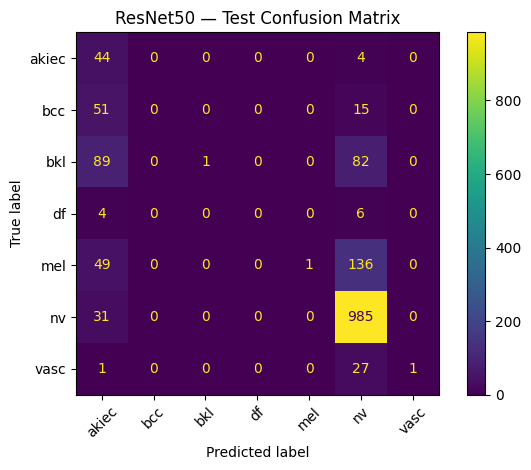

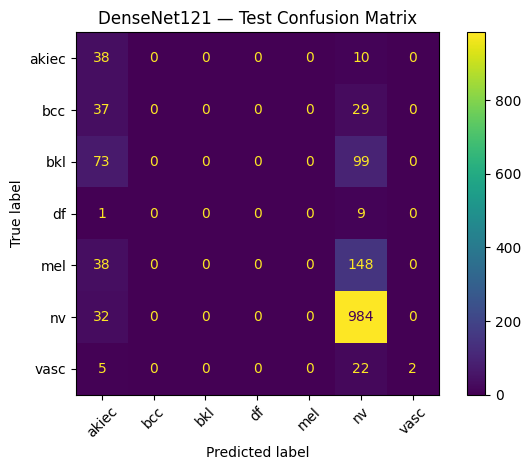

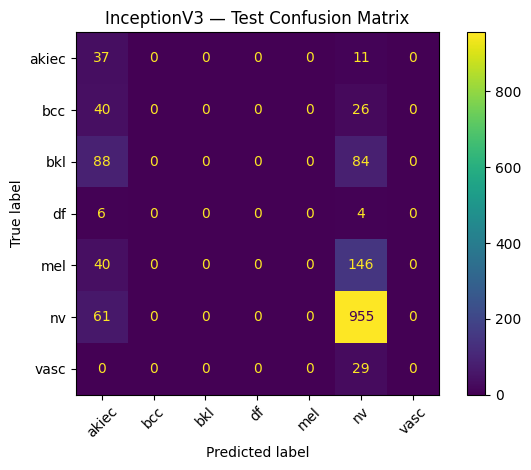

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

project_path = "/content/drive/MyDrive/SKINDERMO"
results_path = os.path.join(project_path, "evaluation_results")
os.makedirs(results_path, exist_ok=True)

class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

comparison = []

for name, result in results.items():
    y_pred = result["predictions"]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    })

    cm = confusion_matrix(y_true, y_pred, labels=range(7))
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=class_names
    )
    display.plot(xticks_rotation=45, values_format="d")
    plt.title(f"{name} — Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        os.path.join(results_path, f"{name.lower()}_confusion_matrix.png"),
        dpi=150
    )
    plt.show()
    plt.close()

comparison_df = pd.DataFrame(comparison)
comparison_df.to_csv(
    os.path.join(results_path, "model_comparison.csv"), index=False
)

display(comparison_df.round(3))
print("Results saved to:", results_path)

In [ ]:
import os

results_path = "/content/drive/MyDrive/SKINDERMO/evaluation_results"

print("Saved result files:")
print(os.listdir(results_path))

Saved result files:
['resnet50_confusion_matrix.png', 'densenet121_confusion_matrix.png', 'inceptionv3_confusion_matrix.png', 'model_comparison.csv']


In [ ]:
import pandas as pd
from IPython.display import display as show_table

comparison_df = pd.read_csv(
    "/content/drive/MyDrive/SKINDERMO/evaluation_results/model_comparison.csv"
)

show_table(comparison_df.round(3))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,ResNet50,0.676,0.564,0.276,0.176,0.590
1,DenseNet121,0.671,0.275,0.261,0.180,0.576
2,InceptionV3,0.650,0.128,0.244,0.153,0.567


In [ ]:
for name, model in loaded_models.items():
    print(f"\n{name}")
    for layer in model.layers:
        if any(word in layer.name.lower()
               for word in ["lambda", "rescaling", "preprocess"]):
            print(layer.name, type(layer).__name__)


ResNet50
lambda Lambda

DenseNet121
lambda Lambda

InceptionV3
rescaling Rescaling


In [ ]:
for name, model in loaded_models.items():
    print(f"\n--- {name} ---")

    for layer in model.layers:
        if layer.name.lower() in ["lambda", "rescaling"]:
            print("Layer:", layer.name)
            print("Configuration:", layer.get_config())


--- ResNet50 ---
Layer: lambda
Configuration: {'name': 'lambda', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'function': {'module': 'builtins', 'class_name': 'function', 'config': 'preprocess_input', 'registered_name': 'function'}, 'arguments': {}}

--- DenseNet121 ---
Layer: lambda
Configuration: {'name': 'lambda', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'function': {'module': 'builtins', 'class_name': 'function', 'config': 'preprocess_input', 'registered_name': 'function'}, 'arguments': {}}

--- InceptionV3 ---
Layer: rescaling
Configuration: {'name': 'rescaling', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'scale': 0.00784313725490196, 'offset': -1}


In [ ]:
import os

project_path = "/content/drive/MyDrive/SKINDERMO"

print("Project files:")
for item in os.listdir(project_path):
    print(item)

Project files:
HAM10000_metadata.csv
HAM10000_images_part_1
HAM10000_images_part_2
splits
models
resnet50_training_history_reconstructed.csv
densenet121_training_history_reconstructed.csv
evaluation_results


In [ ]:

%%writefile /content/drive/MyDrive/SKINDERMO/app.py
import streamlit as st
from PIL import Image

st.set_page_config(
    page_title="SKINDERMO | AI Skin Research",
    page_icon="✳",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ---------- CUSTOM DESIGN ----------
st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700&family=Manrope:wght@400;500;600;700;800&display=swap');

.stApp {
    background: #09111F;
    color: #EAF1FA;
    font-family: 'DM Sans', sans-serif;
}
[data-testid="stHeader"] { background: transparent; }
[data-testid="stSidebar"] {
    background: #0D1828;
    border-right: 1px solid #203047;
}
.block-container {
    max-width: 1250px;
    padding-top: 2rem;
    padding-bottom: 3rem;
}
h1, h2, h3 { font-family: 'Manrope', sans-serif !important; }
p, label, span { letter-spacing: .1px; }

.brand {
    font-family: 'Manrope', sans-serif;
    font-size: 25px;
    font-weight: 800;
    color: #F2F7FF;
    letter-spacing: -1px;
}
.brand span { color: #42DFC0; }
.muted { color: #93A5BD; }
.eyebrow {
    color: #42DFC0;
    font-size: 12px;
    font-weight: 700;
    letter-spacing: 2px;
    text-transform: uppercase;
}
.hero {
    padding: 34px 36px;
    border: 1px solid #243951;
    border-radius: 24px;
    background: linear-gradient(120deg, #12263A 0%, #102033 55%, #102C35 100%);
    margin: 14px 0 25px 0;
}
.hero h1 {
    font-size: clamp(30px, 4vw, 46px);
    line-height: 1.15;
    margin: 12px 0;
    letter-spacing: -1.8px;
}
.hero p { color: #B0C0D3; font-size: 16px; line-height: 1.8; }
.panel {
    background: #101C2D;
    border: 1px solid #26374D;
    border-radius: 19px;
    padding: 24px;
    min-height: 160px;
}
.panel-title { font-size: 17px; font-weight: 700; margin-bottom: 7px; }
.small { color: #91A3BA; font-size: 13px; line-height: 1.65; }
.tag {
    display: inline-block;
    padding: 6px 10px;
    border-radius: 30px;
    border: 1px solid #28584F;
    color: #60E5C8;
    background: #122D30;
    font-size: 11px;
    font-weight: 700;
}
.section-title {
    font-family: 'Manrope', sans-serif;
    font-size: 23px;
    font-weight: 800;
    margin: 20px 0 5px 0;
}
div[data-testid="stFileUploader"] {
    border: 1px dashed #3B7280;
    border-radius: 15px;
    padding: 14px;
    background: #0D1928;
}
.stButton > button {
    background: #42DFC0;
    color: #071820;
    border: none;
    border-radius: 11px;
    min-height: 46px;
    font-weight: 800;
    width: 100%;
}
.stButton > button:hover {
    background: #7CEBD5;
    color: #071820;
    border: none;
}
div[data-baseweb="select"] > div {
    background: #111F31;
    border-color: #30445B;
    border-radius: 10px;
}
hr { border-color: #26374D; }
.footer {
    color: #8193AA;
    font-size: 12px;
    text-align: center;
    padding: 25px 0 5px;
}
</style>
""", unsafe_allow_html=True)

# ---------- SIDEBAR ----------
with st.sidebar:
    st.markdown('<div class="brand">✳ SKIN<span>DERMO</span></div>',
                unsafe_allow_html=True)
    st.markdown('<p class="small">AI SKIN RESEARCH PLATFORM</p>',
                unsafe_allow_html=True)
    st.divider()

    st.markdown("### Workspace")
    page = st.radio(
        "Navigation",
        ["Image Analysis", "About the Project"],
        label_visibility="collapsed"
    )

    st.divider()
    st.markdown("#### Model configuration")
    selected_model = st.selectbox(
        "Classification model",
        ["ResNet50", "DenseNet121", "InceptionV3"]
    )

    st.markdown(
        '<p class="small">HAM10000 · 7 classes · Research prototype</p>',
        unsafe_allow_html=True
    )
    st.divider()
    st.markdown(
        '<p class="small">Built for academic research and learning.</p>',
        unsafe_allow_html=True
    )

# ---------- HEADER ----------
st.markdown(
    '<div class="eyebrow">✳ INTELLIGENT SKIN IMAGE RESEARCH</div>',
    unsafe_allow_html=True
)

if page == "Image Analysis":
    st.markdown("""
    <div class="hero">
      <div class="tag">AI-POWERED · RESEARCH DEMO</div>
      <h1>Skin image analysis,<br>reimagined.</h1>
      <p>Explore an experimental deep-learning classifier for skin-lesion
      images. Upload an image to begin your research workflow.</p>
    </div>
    """, unsafe_allow_html=True)

    left, right = st.columns([1.05, 0.95], gap="large")

    with left:
        st.markdown('<div class="section-title">01 &nbsp; Upload image</div>',
                    unsafe_allow_html=True)
        st.markdown(
            '<p class="small">Select a clear JPG, JPEG, or PNG image.</p>',
            unsafe_allow_html=True
        )

        uploaded_file = st.file_uploader(
            "Drop your image here or browse files",
            type=["jpg", "jpeg", "png"],
            label_visibility="collapsed"
        )

        if uploaded_file:
            image = Image.open(uploaded_file).convert("RGB")
            st.image(image, use_container_width=True)
            st.markdown(
                f'<p class="small">File: {uploaded_file.name} · '
                f'{image.width} × {image.height} pixels</p>',
                unsafe_allow_html=True
            )
        else:
            st.markdown("""
            <div class="panel">
              <div style="font-size:38px">↥</div>
              <div class="panel-title">Your image goes here</div>
              <p class="small">Upload a skin-lesion image to preview it.
              Model prediction will be available after model integration.</p>
              <span class="tag">JPG · JPEG · PNG</span>
            </div>
            """, unsafe_allow_html=True)

    with right:
        st.markdown('<div class="section-title">02 &nbsp; Analysis setup</div>',
                    unsafe_allow_html=True)
        st.markdown(f"""
        <div class="panel">
          <div class="eyebrow">SELECTED MODEL</div>
          <h2 style="margin:10px 0 4px">{selected_model}</h2>
          <p class="small">Pre-trained convolutional neural network
          selected for the experimental classification workflow.</p>
          <hr>
          <div class="eyebrow">OUTPUT CATEGORIES</div>
          <p class="small">akiec · bcc · bkl · df · mel · nv · vasc</p>
        </div>
        """, unsafe_allow_html=True)

        st.write("")
        st.markdown("""
        <div class="panel">
          <div class="panel-title">What happens next?</div>
          <p class="small">1. Preview the uploaded image<br>
          2. Prepare the image for the selected model<br>
          3. Generate a predicted class and confidence score<br>
          4. Review the result with the research limitations</p>
        </div>
        """, unsafe_allow_html=True)

        st.write("")
        if st.button("✳  Run image analysis", disabled=uploaded_file is None):
            st.info(
                "The interface is ready. The model inference pipeline "
                "must be connected and verified before predictions can run."
            )

    st.divider()
    st.markdown('<div class="section-title">Research safeguards</div>',
                unsafe_allow_html=True)
    c1, c2, c3 = st.columns(3)

    with c1:
        st.markdown("""
        <div class="panel">
          <div class="panel-title">◈ Experimental model</div>
          <p class="small">Predictions are produced by a model trained for
          an academic project.</p>
        </div>
        """, unsafe_allow_html=True)
    with c2:
        st.markdown("""
        <div class="panel">
          <div class="panel-title">◇ Dataset-based</div>
          <p class="small">The project uses the HAM10000 dataset and
          seven image-label categories.</p>
        </div>
        """, unsafe_allow_html=True)
    with c3:
        st.markdown("""
        <div class="panel">
          <div class="panel-title">♡ Not a diagnosis</div>
          <p class="small">This tool cannot diagnose conditions or replace
          a qualified healthcare professional.</p>
        </div>
        """, unsafe_allow_html=True)

else:
    st.markdown("""
    <div class="hero">
      <div class="eyebrow">ABOUT THE PROJECT</div>
      <h1>Inside SKINDERMO.</h1>
      <p>An academic prototype exploring deep learning for skin-lesion
      image classification.</p>
    </div>
    """, unsafe_allow_html=True)

    st.markdown("""
    <div class="panel">
      <div class="panel-title">Project overview</div>
      <p class="small">SKINDERMO explores transfer learning using
      ResNet50, DenseNet121 and InceptionV3. The dataset contains
      seven categories: akiec, bcc, bkl, df, mel, nv and vasc.</p>
      <hr>
      <div class="panel-title">Current limitations</div>
      <p class="small">The test dataset is class-imbalanced, and initial
      results show poor performance for multiple categories. Evaluation
      and preprocessing must be verified before interpreting predictions.</p>
    </div>
    """, unsafe_allow_html=True)

st.markdown("""
<div class="footer">
  SKINDERMO · Academic AI prototype · Not for medical use<br>
  Model predictions must not be used for diagnosis or treatment decisions.
</div>
""", unsafe_allow_html=True)


Writing /content/drive/MyDrive/SKINDERMO/app.py


In [ ]:
import os

app_path = "/content/drive/MyDrive/SKINDERMO/app.py"

print("App file exists:", os.path.exists(app_path))
print("App size:", os.path.getsize(app_path), "bytes")

App file exists: True
App size: 9137 bytes


In [ ]:
!pip -q install streamlit

In [ ]:

%%writefile /content/drive/MyDrive/SKINDERMO/app.py
import os
import streamlit as st
import numpy as np
import tensorflow as tf
from PIL import Image

from tensorflow.keras.applications.resnet50 import (
    preprocess_input as resnet_preprocess
)
from tensorflow.keras.applications.densenet import (
    preprocess_input as densenet_preprocess
)

st.set_page_config(
    page_title="SKINDERMO | AI Skin Research",
    page_icon="🔬",
    layout="wide"
)

PROJECT = "/content/drive/MyDrive/SKINDERMO"
MODEL_DIR = os.path.join(PROJECT, "models")
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

MODEL_FILES = {
    "ResNet50": "resnet50_best.keras",
    "DenseNet121": "densenet121_best.keras",
    "InceptionV3": "inceptionv3_best.keras",
}

@st.cache_resource
def load_model(model_name):
    path = os.path.join(MODEL_DIR, MODEL_FILES[model_name])

    if model_name == "ResNet50":
        return tf.keras.models.load_model(
            path,
            custom_objects={"preprocess_input": resnet_preprocess},
            compile=False
        )

    if model_name == "DenseNet121":
        return tf.keras.models.load_model(
            path,
            custom_objects={"preprocess_input": densenet_preprocess},
            compile=False
        )

    return tf.keras.models.load_model(path, compile=False)


st.markdown("""
<style>
.stApp {background:#09111F;color:#EAF1FA}
.block-container {max-width:1200px;padding-top:2rem}
[data-testid="stSidebar"] {background:#0D1828}
.hero {
 padding:32px;border-radius:22px;
 background:linear-gradient(120deg,#12263A,#102C35);
 border:1px solid #294357;margin:20px 0
}
.hero h1 {font-size:42px;color:#F2F7FF}
.hero p {color:#B0C0D3;font-size:16px}
.panel {
 padding:22px;border-radius:16px;background:#101C2D;
 border:1px solid #26374D;margin-bottom:14px
}
.stButton>button {
 background:#42DFC0;color:#071820;border:0;
 border-radius:10px;font-weight:700;min-height:44px
}
</style>
""", unsafe_allow_html=True)

with st.sidebar:
    st.markdown("## ✳ SKINDERMO")
    st.caption("AI SKIN RESEARCH PLATFORM")
    st.divider()
    model_name = st.selectbox("Choose model", list(MODEL_FILES))
    st.caption("HAM10000 · Seven classes")
    st.divider()
    st.caption("Academic prototype only — not for medical use.")

st.markdown("""
<div class="hero">
  <p>✳ AI-POWERED SKIN IMAGE RESEARCH</p>
  <h1>Skin image analysis,<br>reimagined.</h1>
  <p>Upload an image to explore the experimental image-classification model.</p>
</div>
""", unsafe_allow_html=True)

st.warning(
    "Research demonstration only. This tool cannot diagnose skin disease "
    "or guide treatment. Do not use its output for healthcare decisions."
)

left, right = st.columns([1, 1], gap="large")

with left:
    st.markdown("### 01 · Upload image")
    uploaded = st.file_uploader(
        "Choose a skin-lesion image",
        type=["jpg", "jpeg", "png"]
    )

    if uploaded:
        image = Image.open(uploaded).convert("RGB")
        st.image(image, caption="Uploaded image", use_container_width=True)
        st.caption(f"Image dimensions: {image.width} × {image.height}")

with right:
    st.markdown("### 02 · Model analysis")
    st.markdown(f"""
    <div class="panel">
      <h3>{model_name}</h3>
      <p>Seven-class experimental classifier</p>
      <p style="color:#42DFC0">● Model checkpoint selected</p>
    </div>
    """, unsafe_allow_html=True)

    if st.button("Run image classification", disabled=uploaded is None):
        try:
            with st.spinner("Loading model and processing image..."):
                model = load_model(model_name)
                size = 299 if model_name == "InceptionV3" else 224

                resized = image.resize((size, size))
                pixels = np.asarray(resized, dtype=np.float32)
                batch = np.expand_dims(pixels, axis=0)

                probabilities = model.predict(batch, verbose=0)[0]
                predicted_index = int(np.argmax(probabilities))

            st.markdown("### Experimental model output")
            st.metric("Predicted class", CLASSES[predicted_index])
            st.caption(
                "This is a dataset label, not a medical diagnosis."
            )

            st.markdown("#### Model scores")
            for i, class_name in enumerate(CLASSES):
                st.write(f"**{class_name}** — {probabilities[i] * 100:.2f}%")
                st.progress(float(np.clip(probabilities[i], 0, 1)))

            st.info(
                "Scores may be unreliable. The project's test results show "
                "poor recognition for several classes, so do not interpret "
                "this output as clinical evidence."
            )

        except Exception as error:
            st.error(f"Could not run classification: {error}")

st.divider()
st.markdown("### About this project")
a, b, c = st.columns(3)
a.markdown("**Three CNN models**\n\nResNet50, DenseNet121 and InceptionV3.")
b.markdown("**Seven dataset labels**\n\nakiec, bcc, bkl, df, mel, nv, vasc.")
c.markdown("**Research limitations**\n\nNot validated for medical diagnosis.")
st.caption("SKINDERMO · Academic AI prototype · Not for medical use")


Overwriting /content/drive/MyDrive/SKINDERMO/app.py


In [ ]:
!streamlit run /content/drive/MyDrive/SKINDERMO/app.py \
    --server.port 8501 \
    --server.headless true \
    > /content/streamlit.log 2>&1 &